In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

Question 1

- Load the CSV
- Display shape
- data types
- descriptive statistics
- missing values
- The first five rows

In [4]:
print("Shape:", df.shape)        
print()
print("Data types:", df.dtypes)
print()
print("Descriptive statistics:", df.describe(include="all").T)
print()
print("Missing values:", df.isna().sum()) 
print()
print("First five rows:", df.head())
print()
print("Correlation matrix:", df.drop(columns="ticket_id").corr().round(3))

Shape: (240, 6)

Data types: ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:                        count unique    top freq       mean        std  min  \
ticket_id                240    240  T0001    1        NaN        NaN  NaN   
complexity_score       240.0    NaN    NaN  NaN   5.491667   2.979697  1.0   
lines_changed          240.0    NaN    NaN  NaN  54.820833  26.145017  1.0   
team_experience_years  240.0    NaN    NaN  NaN   6.105417   3.391426  0.5   
reopened               240.0    NaN    NaN  NaN   0.233333   0.423836  0.0   
resolution_hours       240.0    NaN    NaN  NaN  19.361125  10.035058  0.5   

                          25%    50%      75%    max  
ticket_id                 NaN    NaN      NaN    NaN  
complexity_score          3.0    5.5      8.0   10.0  
lines_changed         

Question 2

Define `resolution_hours` as y. Exclude `ticket_id` from X. Write down which features are available at the intended prediction time and justify exclusions.

- `ticket_id` is excluded because it is only an identifier and its value does not describe the ticket’s work or help predict how long it will take. For a prediction made when a ticket is received or assigned, `complexity_score` should be available if it is assessed at that time, and `team_experience_years` should be available if the assigned team is already known. `lines_changed` is excluded because it may only be known after work has been done. `reopened` is excluded because it may describe an event that happens after the initial resolution. Using information recorded after the prediction time could make the model appear more accurate than it would be in real use.

In [7]:
target = "resolution_hours"
features = ["complexity_score", "team_experience_years"]

X = df[features]
y = df[target]
print(X)
print(y)

     complexity_score  team_experience_years
0                   6                    5.6
1                   9                   11.5
2                   6                    3.3
3                   5                    9.6
4                   3                    6.4
..                ...                    ...
235                10                    8.3
236                 7                    3.1
237                 3                    3.7
238                 3                    5.9
239                 4                    1.9

[240 rows x 2 columns]
0      24.77
1      33.43
2      17.82
3      19.54
4      11.04
       ...  
235    35.77
236    23.79
237    17.82
238    17.87
239    13.53
Name: resolution_hours, Length: 240, dtype: float64


Question 3

Split data into training and test sets (suggested 80/20, random_state=42). Do not use the test set to choose model settings.

- The test set is locked away here and is not used to choose any setting. Validation strategy: 5-fold CV in the training set (train on 4 folds, validate on the 5th, repeat 5 times). All model/alpha choices use this only.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (192, 2)  Test: (48, 2)


* A helper function that evaluates any model the same way, it'll score it with 5 fold cross validation on the training data and then fit it and test it once on the test set and save the results and predictions for the comparison table and plots

In [19]:
def cv_scores(model, Xtr, ytr):
    """5-fold CV on the training data only (uses cross_val_score from the starter)"""
    mae = -cross_val_score(model, Xtr, ytr, cv=cv, scoring="neg_mean_absolute_error")
    rmse = -cross_val_score(model, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(model, Xtr, ytr, cv=cv, scoring="r2")
    return dict(cv_MAE=mae.mean(), cv_RMSE=rmse.mean(), cv_RMSE_sd=rmse.std(), cv_R2=r2.mean())
 
def fit_and_test(model, Xtr, ytr, Xte, yte):
    """Fit on training data, evaluate once on the test data"""
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    out = dict(test_MAE=mean_absolute_error(yte, p),
               test_RMSE=np.sqrt(mean_squared_error(yte, p)),
               test_R2=r2_score(yte, p))
    ptr = model.predict(Xtr)
    out.update(train_RMSE=np.sqrt(mean_squared_error(ytr, ptr)), train_R2=r2_score(ytr, ptr))
    return out, p
 
models, results, preds = {}, {}, {}
 
def evaluate(name, model):
    """CV on train + one test evaluation; stores model, results and predictions"""
    models[name] = model
    row = cv_scores(model, X_train, y_train)
    t, p = fit_and_test(model, X_train, y_train, X_test, y_test)
    row.update(t)
    results[name] = row
    preds[name] = p
    return row

Question 4

Fit a `DummyRegressor(strategy='mean')` baseline and record its test metrics.

In [23]:
b = evaluate("Dummy (mean)", DummyRegressor(strategy="mean"))
print({k: round(v, 3) for k, v in b.items() if k.startswith("test")})

{'test_MAE': 9.114, 'test_RMSE': np.float64(10.598), 'test_R2': -0.021}


Question 5

Fit `LinearRegression` on the selected features. Record MAE, RMSE, and R²

In [24]:
l = evaluate("Linear", make_pipeline(StandardScaler(), LinearRegression()))
print({k: round(float(v), 3) for k, v in l.items() if k.startswith("test")})

{'test_MAE': 2.906, 'test_RMSE': 3.572, 'test_R2': 0.884}


Question 6

Create a pipeline with `PolynomialFeatures` and `StandardScaler` followed by linear regression. Compare degrees 2 and 3 using cross-validation on the training set.

In [25]:
for d in (2, 3):
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    r = evaluate(f"Poly deg{d}", pipe)
    print(f"degree {d}: CV RMSE = {r['cv_RMSE']:.3f} (+/- {r['cv_RMSE_sd']:.3f}), "
          f"CV MAE = {r['cv_MAE']:.3f}, CV R2 = {r['cv_R2']:.3f}")

degree 2: CV RMSE = 3.832 (+/- 0.461), CV MAE = 3.131, CV R2 = 0.844
degree 3: CV RMSE = 3.877 (+/- 0.314), CV MAE = 3.162, CV R2 = 0.841


Question 7

Fit Ridge and Lasso models using a pipeline that scales features. Select alpha with cross-validation or a small validation grid. Record the selected value and results.

In [27]:
alphas = np.logspace(-3, 2, 30)         

lasso_alphas = np.logspace(-3, 1, 30)      
 
 
def pick_alpha(make_model, grid):
    """Small validation grid: mean 5-fold CV RMSE (training set only) for each alpha."""
    rmses = []
    for a in grid:
        s = cross_val_score(make_model(a), X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error")
        rmses.append(-s.mean())
    rmses = np.array(rmses)
    return grid[rmses.argmin()], rmses
 
 
ridge_alpha, ridge_curve = pick_alpha(lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)), alphas)
lasso_alpha, lasso_curve = pick_alpha(
    lambda a: make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)), lasso_alphas)
print(f"Ridge selected alpha = {ridge_alpha:.4f}") 
print(f"Lasso selected alpha = {lasso_alpha:.4f}")    
evaluate("Ridge (linear feats)", make_pipeline(StandardScaler(), Ridge(alpha=ridge_alpha)))
evaluate("Lasso (linear feats)", make_pipeline(StandardScaler(), Lasso(alpha=lasso_alpha, max_iter=100000)))
 
ridge3_alpha, _ = pick_alpha(
    lambda a: make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=a)), alphas)
lasso3_alpha, _ = pick_alpha(
    lambda a: make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                            Lasso(alpha=a, max_iter=200000)), lasso_alphas)
print(f"Ridge on degree-3 features: selected alpha = {ridge3_alpha:.4f}")   
print(f"Lasso on degree-3 features: selected alpha = {lasso3_alpha:.4f}")   
evaluate("Ridge (poly deg3)", make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                                            Ridge(alpha=ridge3_alpha)))
evaluate("Lasso (poly deg3)", make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                                            Lasso(alpha=lasso3_alpha, max_iter=200000)))
 
res = pd.DataFrame(results).T
res.index.name = "model"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("\nAll results (CV on training set; test evaluated once)")
print(res.astype(float).round(3))
res.astype(float).round(4).to_csv("results_table.csv")

Ridge selected alpha = 0.5736
Lasso selected alpha = 0.0010
Ridge on degree-3 features: selected alpha = 1.8874
Lasso on degree-3 features: selected alpha = 0.0329

All results (CV on training set; test evaluated once)
                      cv_MAE  cv_RMSE  cv_RMSE_sd  cv_R2  test_MAE  test_RMSE  test_R2  train_RMSE  train_R2
model                                                                                                       
Dummy (mean)           8.448    9.884       0.754 -0.023     9.114     10.598   -0.021       9.869     0.000
Linear                 3.168    3.909       0.411  0.838     2.906      3.572    0.884       3.869     0.846
Poly deg2              3.131    3.832       0.461  0.844     3.020      3.741    0.873       3.770     0.854
Poly deg3              3.162    3.877       0.314  0.841     3.140      3.949    0.858       3.702     0.859
Ridge (linear feats)   3.168    3.909       0.414  0.838     2.906      3.571    0.884       3.869     0.846
Lasso (linear feat

- Lasso doesn't need penalty regularization helps when a model has too much flexibility but in here the linear model has only two features and 192 training rows so plain least square is stable and generalises well and both features are useful so lasso has nothing to drop adding penalty would add bias without reducing variance.

- I have tuned ridge and lasso for degree 3 polynomial features becuase degree 3 turns the two features into 9 terms that corrolate with each other, without penalty the model overfits and its coefficients will be large, ridge will reduce the coefficients and lasso reduce them and sets 4 of 9 to zero

Question 8

Plot observed versus predicted values and a residual plot for at least two models. Look for curvature, changing spread, and influential outliers.

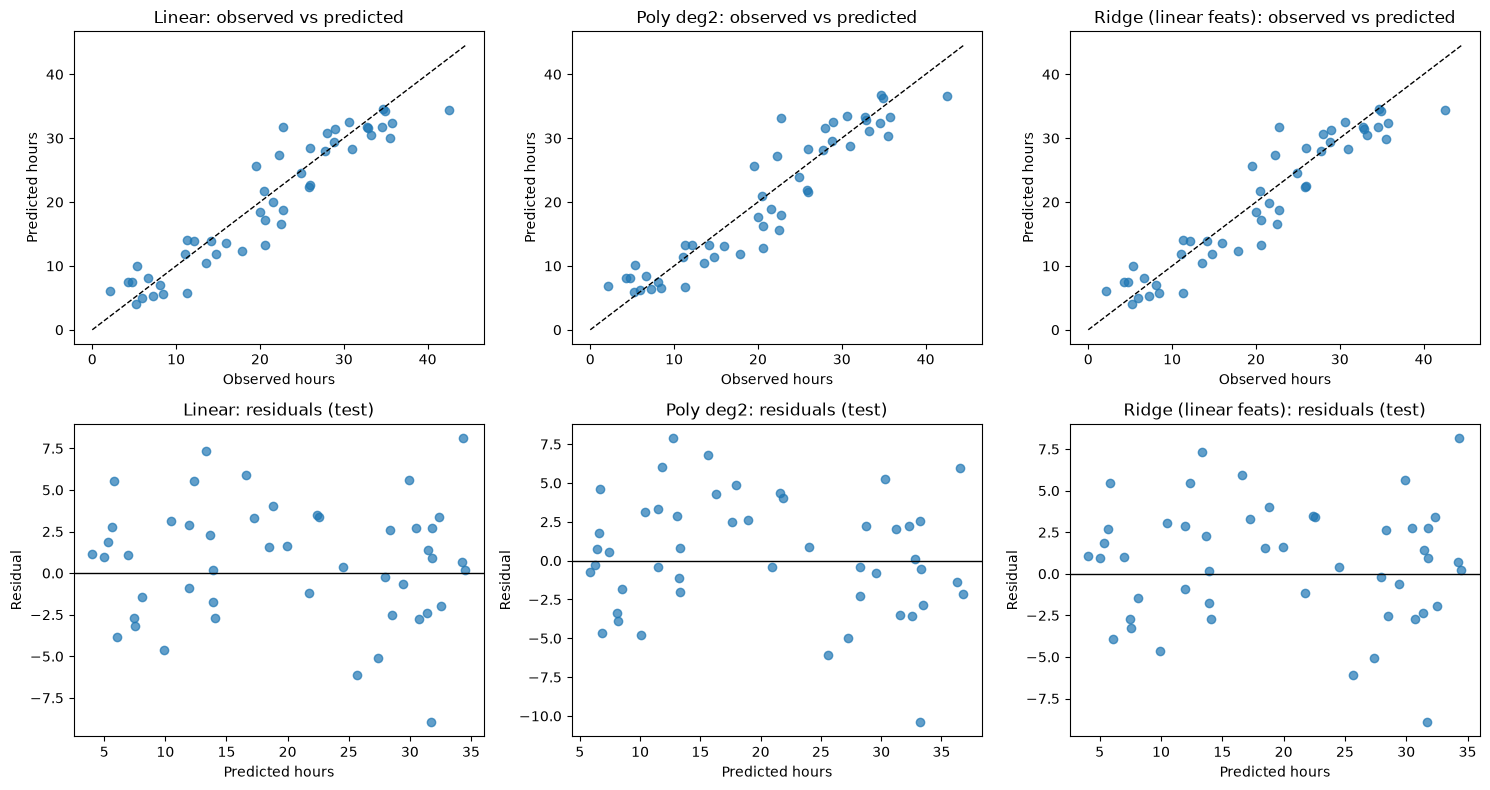

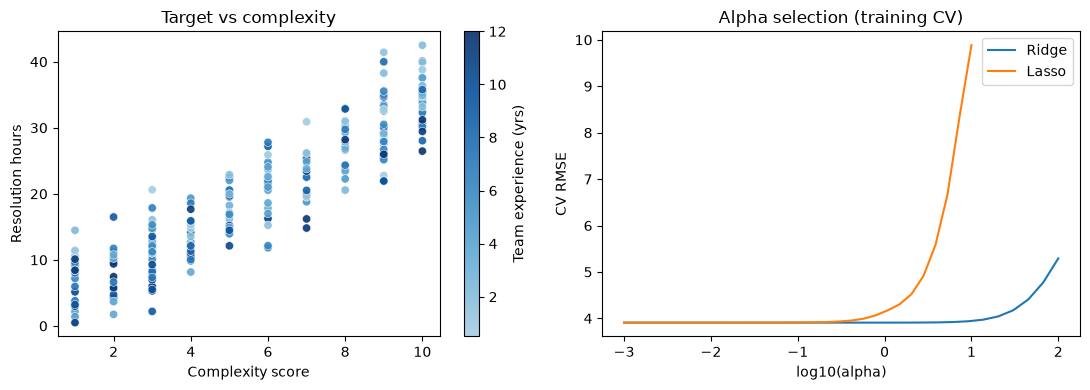

Residual SD, lower half of target / upper half (test): 3.33 3.65
Largest |residual| in training data: 10.57
Mean training residual by complexity score:
{1: 1.87, 2: 0.13, 3: -1.14, 4: -1.01, 5: -0.15, 6: -0.52, 7: -0.91, 8: 0.55, 9: 0.23, 10: 0.96}


In [29]:
chosen = ["Linear", "Poly deg2", "Ridge (linear feats)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, n in enumerate(chosen):
    p = preds[n]
    ax = axes[0, j]
    ax.scatter(y_test, p, alpha=.7)
    lim = [0, max(y_test.max(), p.max()) + 2]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"{n}: observed vs predicted", xlabel="Observed hours", ylabel="Predicted hours")
    ax = axes[1, j]
    ax.scatter(p, y_test - p, alpha=.7)
    ax.axhline(0, color="k", lw=1)
    ax.set(title=f"{n}: residuals (test)", xlabel="Predicted hours", ylabel="Residual")
plt.tight_layout()
plt.savefig("fig_obs_vs_pred_residuals.png", dpi=130)
plt.show()

from matplotlib.colors import ListedColormap     
blue_cmap = ListedColormap(plt.cm.Blues(np.linspace(0.35, 1.0, 256)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(df.complexity_score, df.resolution_hours, c=df.team_experience_years,
                   cmap=blue_cmap, alpha=.9, edgecolors="white", linewidths=.4)
plt.colorbar(sc, ax=ax[0], label="Team experience (yrs)")
ax[0].set(xlabel="Complexity score", ylabel="Resolution hours", title="Target vs complexity")
ax[1].plot(np.log10(alphas), ridge_curve, label="Ridge")
ax[1].plot(np.log10(lasso_alphas), lasso_curve, label="Lasso")
ax[1].set(xlabel="log10(alpha)", ylabel="CV RMSE", title="Alpha selection (training CV)")
ax[1].legend()
plt.tight_layout()
plt.savefig("fig_eda_alpha.png", dpi=130)
plt.show()
 
p = preds["Linear"]
r = y_test.values - p
lo = y_test.values < np.median(y_test)
print("Residual SD, lower half of target / upper half (test):", r[lo].std().round(2), r[~lo].std().round(2))
rt = y_train.values - models["Linear"].predict(X_train)
print("Largest |residual| in training data:", np.abs(rt).max().round(2))
print("Mean training residual by complexity score:")
print(pd.Series(rt).groupby(X_train["complexity_score"].values).mean().round(2).to_dict())

Question 9 

Write a short recommendation: which model would you choose for this dataset, what evidence supports it, and what further data or checks would be needed?

- Linear regression model is better because its average error on the test set is about 3.6 hours, compared with 10.6 hours for the mean baseline and also every extra complexity point adds 3 hours and every extra year of team experience saves 0.3 hours

- Before using data is needed, testing on newer tickets only not just a random split and confirming that both features are really known when the ticket is opened

Question 10

Why is the mean baseline useful even though it ignores all features?

The baseline always predicts the average resolution time that is 19.4 hours for every ticket without using any features. Comparing the models against it shows whether using features like complexity and team experience actually improves predictions. If a model can’t beat this baseline, its added complexity isn’t helping

Question 11

Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

- MAE and RMSE both measure how far the model’s predictions are from the actual resolution times in hours. MAE averages the size of the errors, so each error contributes in proportion to how large it is. RMSE gives larger errors more weight because it squares them before averaging

- On the test set, Linear, Ridge and Lasso had the lowest MAE at 2.906 hours. Ridge had an RMSE of 3.571 hours, while Linear and Lasso had 3.572 hours. That difference is so small that I’d consider them effectively tied

- The lowest-MAE and lowest-RMSE models can differ because RMSE reacts more strongly to large prediction errors. In the cross validation results, degree 3 Lasso had the lowest MAE, while degree 2 had the lowest RMSE. Since the differences are small, I would also consider the cross validation results and prefer the simpler model if performance is similar

Question 12

Did polynomial features improve validation performance? What is the evidence of possible overfitting?

- Polynomial features let the model fit curves instead of only straight line relationships. In my results they did not improve performance much. Degree 2 had a slightly lower cross validation error than linear regression but the difference was small compared with the variation between folds. Degree 3 did worse.

- There is overfitting as the models got more complex their training error went down but their test error went up. The test R square also fell from 0.884 for linear regression to 0.858 for degree 3. This suggests the more flexible models fit the training data better but did not predict unseen tickets as well.

Question 13

How did regularization affect performance and coefficient magnitudes?

- Regularization puts a penalty on large coefficient which makes the model to stay simple and ridge and lasso discourage the model from relying too heavily on large coefficients. With only two features they barely changed the model or its test error. With the more complex degree-3 model they made the coefficients smaller. Lasso also removed some terms by setting their coefficients to zero. This improved the degree-3 model’s test error

Question 14

Why is scaling included in the Ridge/Lasso pipeline?

- I scaled the features so they were on similar measurement scales before applying Ridge or Lasso otherwise the penalty could affect features unevenly just because their values use different scales and scaling inside the pipeline also means it is calculated separately within each training fold during cross validation

Question 15

Identify one potential leakage issue in the dataset and explain how you handled it.

- I left out lines_changed because it can be known after the work is done and reopened because it can be known after the ticket is closed and including them made the scores look better but that wouldn't reflect how the model could perform at the time we want to make a prediction

Question 16

Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.

- For tickets collected over time a random split could let the model learn from newer tickets and then be tested on older ones. To better represent future use I would train on earlier tickets and test on later tickets. If many tickets come from the same teams I would also check performance on teams kept separate from the training data

Question 17

What additional tests would you perform before deploying this model?

- I would test the model on newer tickets, confirm that its input features are known when predictions are made and investigate the tickets where its errors are largest. I would also check whether it can make unrealistic predictions like negative resolution hours and whether its performance stays stable across different data splits. Before relying on it I would compare its predictions with human estimates and monitor its performance over time